# Assignment 2

## Students: <br>

Anton Maksymchuk Netterström <br>
Mauritz Almgren

In [2]:
%pip install ucimlrepo pandas numpy scikit-learn matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


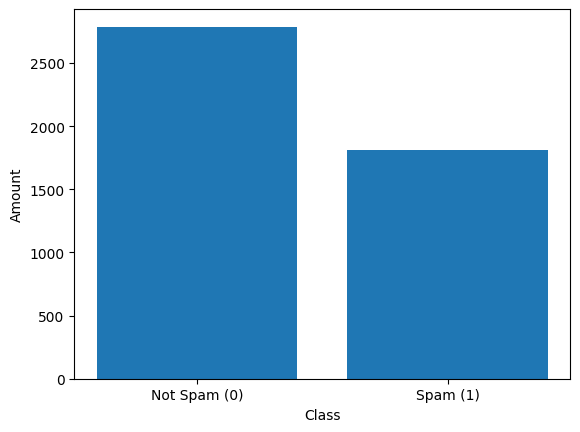

In [3]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from scipy.stats import rankdata

# Used to fetch the dataset
spambase = fetch_ucirepo(id=94)
# All features in the dataset
X = spambase.data.features
# y is the Class with spam (1) and not spam (0)
y = spambase.data.targets

counts = y["Class"].value_counts()

plt.bar(counts.index, counts.values)
plt.xticks(counts.index, ["Not Spam (0)", "Spam (1)"])
plt.xlabel("Class")
plt.ylabel("Amount")
plt.show()

Ranking of fit time for each model

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, stratify=y)

skf = StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

RF = RandomForestClassifier()
KNN = KNeighborsClassifier(n_neighbors=5) # Use default value for k-number neighbors
BN = GaussianNB()

y_train = np.ravel(y_train)

scores_RF = pd.DataFrame(cross_validate(RF, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))
scores_KNN = pd.DataFrame(cross_validate(KNN, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))
scores_NB = pd.DataFrame(cross_validate(BN, X_train, y_train, cv=skf, scoring=["accuracy", "f1"]))

# Dataframe for Fit time
fit_time_df = pd.DataFrame()

fit_time_df["Random Forest"] = scores_RF["fit_time"].round(6)
fit_time_df["KNN"] = scores_KNN["fit_time"].round(6)
fit_time_df["Naive Bayes"] = scores_NB["fit_time"].round(6)
fit_time_df_tot = fit_time_df.copy()

# Add avg and stdev for each model
fit_time_df_tot.loc["avg"] = [np.mean(scores_RF["fit_time"]), np.mean(scores_KNN["fit_time"]), np.mean(scores_NB["fit_time"])]
fit_time_df_tot.loc["stdev"] = [np.std(scores_RF["fit_time"]), np.std(scores_KNN["fit_time"]), np.std(scores_NB["fit_time"])]

display(fit_time_df_tot)

fit_time_ranks = pd.DataFrame(rankdata(fit_time_df, method="min", axis=1))

time_ranked_df = pd.DataFrame()

# Add rank for each fold for each model
time_ranked_df["Random Forest"] = (
    fit_time_df["Random Forest"].astype(str)
    + " "
    + "("
    + fit_time_ranks[0].astype(str)
    + ")"
)

time_ranked_df["KNN"] = (
    fit_time_df["KNN"].astype(str)
    + " "
    + "("
    + fit_time_ranks[1].astype(str)
    + ")"
)

time_ranked_df["Naive Bayes"] = (
    fit_time_df["Naive Bayes"].astype(str)
    + " "
    + "("
    + fit_time_ranks[2].astype(str)
    + ")"
)
time_ranked_df.loc["avg rank"] = [np.mean(fit_time_ranks[0]), np.mean(fit_time_ranks[1]), np.mean(fit_time_ranks[2])]

display(time_ranked_df)
mean_rank = np.mean(time_ranked_df.loc["avg rank"])


,Random Forest,KNN,Naive Bayes
0,1.664486,0.015357,0.017609
1,2.065744,0.011360,0.020881
2,1.092163,0.013387,0.021585
3,1.191832,0.010285,0.015809
4,1.180118,0.011620,0.017318
5,0.985075,0.012655,0.020050
6,1.025077,0.013841,0.021063
7,1.551935,0.011389,0.018594
8,1.273543,0.012147,0.016258
9,1.446159,0.011890,0.021427


,Random Forest,KNN,Naive Bayes
0,1.664486 (3.0),0.015357 (1.0),0.017609 (2.0)
1,2.065744 (3.0),0.01136 (1.0),0.020881 (2.0)
2,1.092163 (3.0),0.013387 (1.0),0.021585 (2.0)
3,1.191832 (3.0),0.010285 (1.0),0.015809 (2.0)
4,1.180118 (3.0),0.01162 (1.0),0.017318 (2.0)
5,0.985075 (3.0),0.012655 (1.0),0.02005 (2.0)
6,1.025077 (3.0),0.013841 (1.0),0.021063 (2.0)
7,1.551935 (3.0),0.011389 (1.0),0.018594 (2.0)
8,1.273543 (3.0),0.012147 (1.0),0.016258 (2.0)
9,1.446159 (3.0),0.01189 (1.0),0.021427 (2.0)


Rank of F-score for each model

In [28]:
f1_df = pd.DataFrame()

f1_df["Random Forest"] = scores_RF["test_f1"].round(6)
f1_df["KNN"] = scores_KNN["test_f1"].round(6)
f1_df["Naive Bayes"] = scores_NB["test_f1"].round(6)
f1_tot = f1_df.copy()

f1_tot.loc["avg"] = [np.mean(scores_RF["test_f1"]), np.mean(scores_KNN["test_f1"]), np.mean(scores_NB["test_f1"])]
f1_tot.loc["stdev"] = [np.std(scores_RF["test_f1"]), np.std(scores_KNN["test_f1"]), np.std(scores_NB["test_f1"])]

display(f1_tot)
f1_ranked_df = pd.DataFrame()
f1_ranks = pd.DataFrame(rankdata(-f1_df, method="average", axis=1))


f1_ranked_df["Random Forest"] = (
    f1_df["Random Forest"].astype(str)
    + " "
    + "("
    + f1_ranks[0].astype(str)
    + ")"
)

f1_ranked_df["KNN"] = (
    f1_df["KNN"].astype(str)
    + " "
    + "("
    + f1_ranks[1].astype(str)
    + ")"
)

f1_ranked_df["Naive Bayes"] = (
    f1_df["Naive Bayes"].astype(str)
    + " "
    + "("
    + f1_ranks[2].astype(str)
    + ")"
)
f1_ranked_df.loc["avg rank"] = [np.mean(f1_ranks[0]), np.mean(f1_ranks[1]), np.mean(f1_ranks[2])]


display(f1_ranked_df)



,Random Forest,KNN,Naive Bayes
0,0.942966,0.705882,0.808917
1,0.942966,0.765152,0.780186
2,0.932331,0.717949,0.813456
3,0.929889,0.705426,0.813880
4,0.947761,0.778182,0.814815
5,0.955882,0.742424,0.809816
6,0.956522,0.766917,0.803738
7,0.913043,0.686567,0.792683
8,0.936330,0.764045,0.806349
9,0.946970,0.711111,0.806250


,Random Forest,KNN,Naive Bayes
0,0.942966 (1.0),0.705882 (3.0),0.808917 (2.0)
1,0.942966 (1.0),0.765152 (3.0),0.780186 (2.0)
2,0.932331 (1.0),0.717949 (3.0),0.813456 (2.0)
3,0.929889 (1.0),0.705426 (3.0),0.81388 (2.0)
4,0.947761 (1.0),0.778182 (3.0),0.814815 (2.0)
5,0.955882 (1.0),0.742424 (3.0),0.809816 (2.0)
6,0.956522 (1.0),0.766917 (3.0),0.803738 (2.0)
7,0.913043 (1.0),0.686567 (3.0),0.792683 (2.0)
8,0.93633 (1.0),0.764045 (3.0),0.806349 (2.0)
9,0.94697 (1.0),0.711111 (3.0),0.80625 (2.0)


Let $R_j$ denote the **avg rank** for model $j$. The Friedman statistics is then calculated by

$\chi^2_F = \frac{12n}{k(k-1)}\sum_j (R_j - \bar{R})^2 = n\sum_j (R_j - \bar{R})^2$ (For $k = 3$)

<br>

$$
\begin{cases}
\chi^2_F < \chi^2_{0.05,2} \xrightarrow{\text{Cannot reject $H_0$}} \text{No statistics significanse to draw conclusions}\\
\chi^2_F > \chi^2_{0.05,2} \xrightarrow{\text{Proceed to Nemenyi test}} CD = q_\alpha \sqrt{\frac{k(k+1)}{k}} \text{ where } q_\alpha \text{ Is the critical value from Studentized Range-distribution}
\end{cases}
$$

<br>

$\chi^2_{0.05,2}$ = 6.2 for n = 10, k = 3 <br>
$q_\alpha = 2.343$ for $\alpha = 0.05$ (Two tailed)

Friedman and Nemenyi for **Time fit**

In [ ]:

CHI_F = 6.2

friedman = 10*np.sum((time_ranked_df.loc["avg rank"] - mean_rank)**2)

if friedman > CHI_F:
    print("Proceed to Nemanyi test.")
else:
    print("Failed to reject H0")

Proceed to Nemanyi test.


Friedman and Nemenyi for **F-score**

In [19]:
# F-score undersökning

Friedman and Nemenyi for **Accuracy**

In [ ]:
# Accuracy undersökning